In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")



In [15]:
df = pd.read_csv("gender_submission.csv")

df.head()

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [16]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Dataset Shape: (418, 2)

Column Names:
['PassengerId', 'Survived']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   PassengerId  418 non-null    int64
 1   Survived     418 non-null    int64
dtypes: int64(2)
memory usage: 6.7 KB

Statistical Summary:


,PassengerId,Survived
count,418.000000,418.000000
mean,1100.500000,0.363636
std,120.810458,0.481622
min,892.000000,0.000000
25%,996.250000,0.000000
50%,1100.500000,0.000000
75%,1204.750000,1.000000
max,1309.000000,1.000000


In [17]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
PassengerId    0
Survived       0
dtype: int64

Total Missing Values:
0


In [18]:
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("\nDataset Shape After Removing Duplicates:")
print(df.shape)

Duplicate Records: 0

Dataset Shape After Removing Duplicates:
(418, 2)


In [19]:
# Check valid PassengerId values
df = df.dropna(subset=['PassengerId'])

# Check valid Survived values
df = df.dropna(subset=['Survived'])

# Keep only valid survival labels
df = df[df['Survived'].isin([0, 1])]

# Convert columns into integer format
df['PassengerId'] = df['PassengerId'].astype(int)
df['Survived'] = df['Survived'].astype(int)

print("Data Cleaning Completed!")

df.head()

Data Cleaning Completed!


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


In [20]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nFinal Dataset Shape:", df.shape)

Missing Values:
PassengerId    0
Survived       0
dtype: int64

Duplicate Records: 0

Final Dataset Shape: (418, 2)


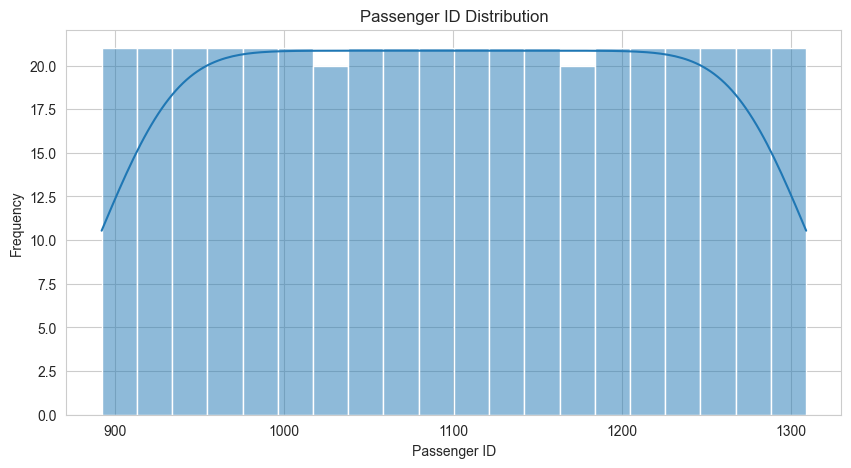

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='PassengerId', bins=20, kde=True)

plt.title("Passenger ID Distribution")
plt.xlabel("Passenger ID")
plt.ylabel("Frequency")

plt.show()

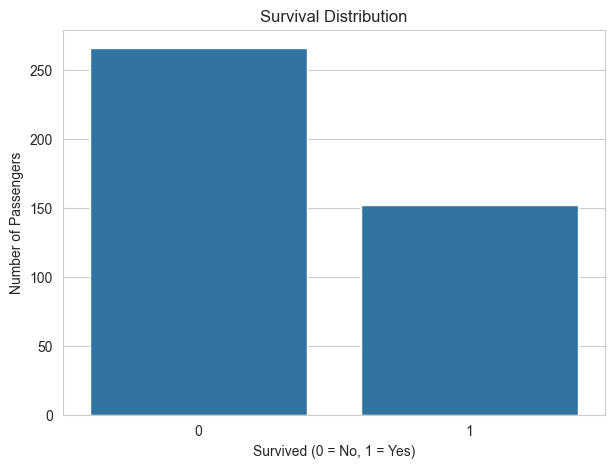

In [22]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Survived')

plt.title("Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

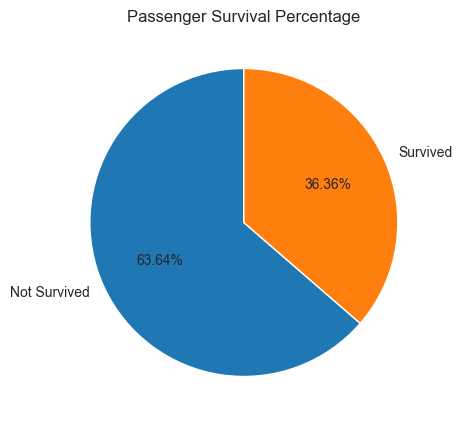

In [23]:
survival_percentage = df['Survived'].value_counts(normalize=True) * 100

plt.figure(figsize=(7, 5))

plt.pie(
    survival_percentage,
    labels=['Not Survived', 'Survived'],
    autopct='%1.2f%%',
    startangle=90
)

plt.title("Passenger Survival Percentage")

plt.show()

In [24]:
# Divide Passenger IDs into ranges
df['Passenger_Range'] = pd.cut(
    df['PassengerId'],
    bins=4
)

# Calculate survival labels in each range
range_analysis = df.groupby(
    'Passenger_Range',
    observed=False
)['Survived'].mean() * 100

print("Passenger ID Range Analysis:")
print(range_analysis)

Passenger ID Range Analysis:
Passenger_Range
(891.583, 996.25]    39.047619
(996.25, 1100.5]     36.538462
(1100.5, 1204.75]    32.692308
(1204.75, 1309.0]    37.142857
Name: Survived, dtype: float64


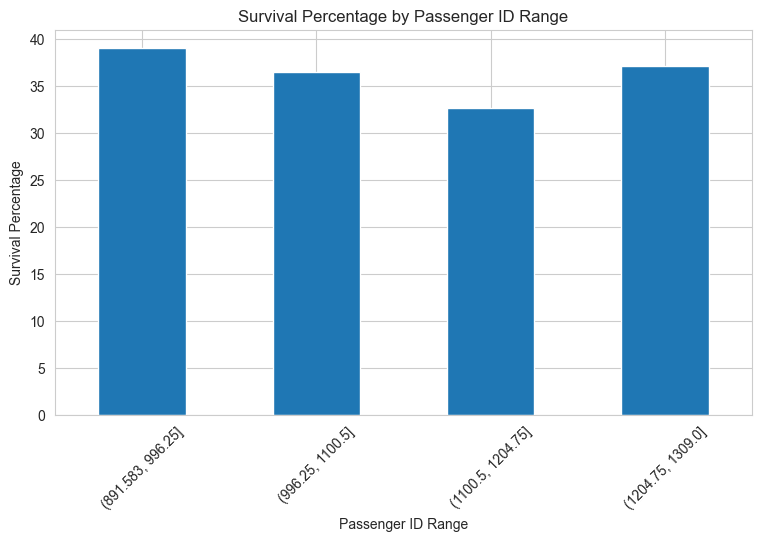

In [26]:
#Visualization
plt.figure(figsize=(9, 5))

range_analysis.plot(kind='bar')

plt.title("Survival Percentage by Passenger ID Range")
plt.xlabel("Passenger ID Range")
plt.ylabel("Survival Percentage")

plt.xticks(rotation=45)
plt.show()

In [27]:
##Identify Patterns and Trends
total_passengers = len(df)

survived = (df['Survived'] == 1).sum()

not_survived = (df['Survived'] == 0).sum()

survival_rate = (survived / total_passengers) * 100

not_survival_rate = (not_survived / total_passengers) * 100

print("========== DATA ANALYSIS ==========")

print("Total Passengers:", total_passengers)

print("Survived:", survived)

print("Not Survived:", not_survived)

print("Survival Percentage:", round(survival_rate, 2), "%")

print("Not Survived Percentage:", round(not_survival_rate, 2), "%")

========== DATA ANALYSIS ==========
Total Passengers: 418
Survived: 152
Not Survived: 266
Survival Percentage: 36.36 %
Not Survived Percentage: 63.64 %
